# 05 · Interpretabilidad, valor de negocio y priorización

Este notebook responde tres preguntas:

1. **¿Por qué predice lo que predice el modelo?** Con valores SHAP.
2. **¿Cuánto vale el modelo para quien decide?** Traduciendo las métricas a delitos.
3. **¿Qué recomendaría el sistema hoy?** Pronóstico y priorización para el próximo mes.

In [1]:
import sys, json, warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from src import modelo, oij, viz

viz.estilo()
FIG = RAIZ / 'reports' / 'figures'
MODELOS = RAIZ / 'models'
ET = viz.ETIQUETAS_DELITO
P = lambda s: pd.Period(s, 'M')

NOMBRE = {
    'media_12': 'Nivel de los últimos 12 meses', 'media_3': 'Media de los últimos 3 meses',
    'lag_1': 'Delitos del mes anterior', 'lag_2': 'Delitos de hace 2 meses', 'lag_3': 'Delitos de hace 3 meses',
    'lag_12': 'Mismo mes del año anterior', 'tendencia': 'Tendencia reciente (3 vs. 12 meses)',
    'tasa_lag_1': 'Tasa del mes anterior', 'tasa_media_12': 'Tasa de los últimos 12 meses',
    'tasa_vecinos_lag_1': 'Tasa en cantones vecinos', 'nacional_lag_1': 'Total nacional del mes anterior',
    'Estacional_canton': 'Estacionalidad local (fiestas)', 'MesNum': 'Mes del año',
    'fines_de_semana': 'Fines de semana del mes', 'dias_mes': 'Días del mes', 'pandemia': 'Pandemia',
    'log_poblacion': 'Población', 'Grupo': 'Perfil delictivo del cantón', 'Delito_cat': 'Tipo de delito',
    'IDS_economica': 'IDS económico', 'IDS_educativa': 'IDS educativo', 'IDS_salud': 'IDS salud',
    'IDS_participacion': 'IDS participación electoral',
}

## 1. Cómo leer las explicaciones

El modelo parte de la **media de los últimos 12 meses** de cada cantón y delito, y la corrige. Los valores SHAP (calculados con el algoritmo TreeSHAP que incluye LightGBM) reparten esa corrección entre las variables.

Como el modelo trabaja en escala logarítmica, cada contribución se lee como un **factor multiplicativo**: un factor de ×1,20 significa que esa variable sube la predicción un 20 %; uno de ×0,90, que la baja un 10 %.

Se analiza el modelo de la prueba final (entrenado con datos hasta 2024) sobre los 21 meses de prueba.

In [2]:
panel = modelo.construir_panel(RAIZ, incluir_mes_siguiente=True)
X = modelo.construir_variables(panel, RAIZ, P('2024-12'))
prueba = X[X['Mes'].between(P('2025-01'), P('2026-09'))].dropna(subset=['media_12']).copy()
booster = lgb.Booster(model_file=str(MODELOS / 'lgbm_poisson.txt'))
contrib = modelo.contribuciones(booster, prueba)
prueba['pred'] = modelo.predecir(booster, prueba)
print('Comprobación (la suma de contribuciones reproduce la predicción):',
      np.allclose(np.exp(contrib.sum(axis=1) + modelo.offset(prueba)), prueba['pred']))

Comprobación (la suma de contribuciones reproduce la predicción): True


## 2. ¿Qué variables pesan más?

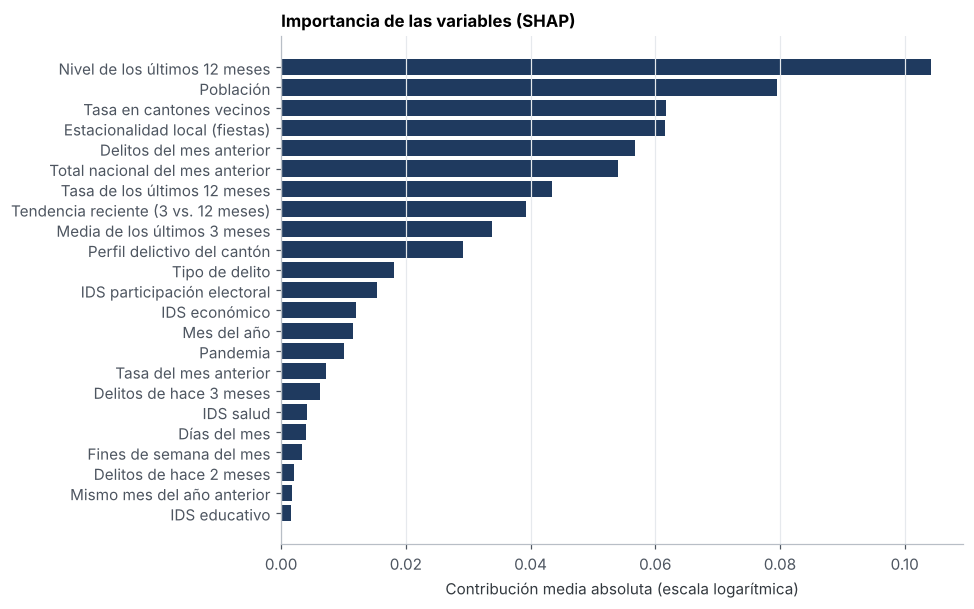

In [3]:
imp = contrib[modelo.VARIABLES].abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([NOMBRE[v] for v in imp.index], imp.values, color=viz.AZUL)
ax.set_xlabel('Contribución media absoluta (escala logarítmica)'); ax.grid(axis='y', visible=False)
ax.set_title('Importancia de las variables (SHAP)')
fig.savefig(FIG / '05_importancia_shap.png')

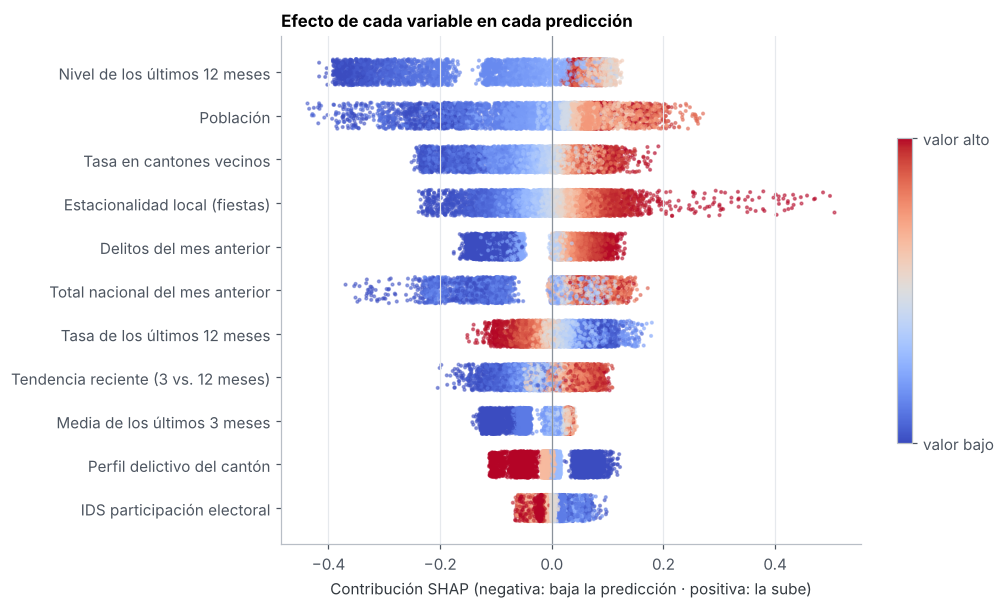

In [4]:
top = imp.index[::-1][:12].drop('Delito_cat', errors='ignore')
muestra = prueba  # todas las predicciones de la prueba
cm = contrib.loc[muestra.index]
fig, ax = plt.subplots(figsize=(8.5, 6))
rng = np.random.default_rng(0)
for i, v in enumerate(top[::-1]):
    x = cm[v].values
    valor = muestra[v].astype(float).rank(pct=True).values
    ax.scatter(x, i + rng.uniform(-0.3, 0.3, len(x)), c=valor, cmap='coolwarm', s=3, alpha=0.5, rasterized=True)
ax.axvline(0, color=viz.GRIS, lw=0.8)
ax.set_yticks(range(len(top)), [NOMBRE[v] for v in top[::-1]]); ax.grid(axis='y', visible=False)
ax.set_xlabel('Contribución SHAP (negativa: baja la predicción · positiva: la sube)')
sm = plt.cm.ScalarMappable(cmap='coolwarm'); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.6, ticks=[0, 1]); cb.ax.set_yticklabels(['valor bajo', 'valor alto'])
ax.set_title('Efecto de cada variable en cada predicción')
fig.savefig(FIG / '05_beeswarm_shap.png')

**Lectura** (rojo = valor alto de la variable, azul = valor bajo):

- **La historia del propio cantón domina**, pero como corrección de la media: si el mes anterior y los últimos tres meses fueron altos, el modelo sube la predicción. Es el **impulso reciente**.
- **Regresión a la media:** cuando la tasa de los últimos 12 meses es muy alta para el tamaño del cantón, el modelo la corrige **a la baja**. Los picos tienden a no repetirse.
- **Los vecinos importan:** si los cantones vecinos tuvieron una tasa alta el mes anterior, el modelo sube la predicción. Confirma el efecto contagio del notebook 03.
- **La estacionalidad local** (que recoge las fiestas cantonales) es una de las cuatro variables más influyentes.
- **El contexto nacional** cuenta: cuando el delito sube en todo el país, sube en cada cantón.
- **El desarrollo social** actúa en la dirección esperada: más participación electoral, menos delito previsto; su peso es menor porque es una foto fija de 2023.

## 3. Cómo actúan las variables clave

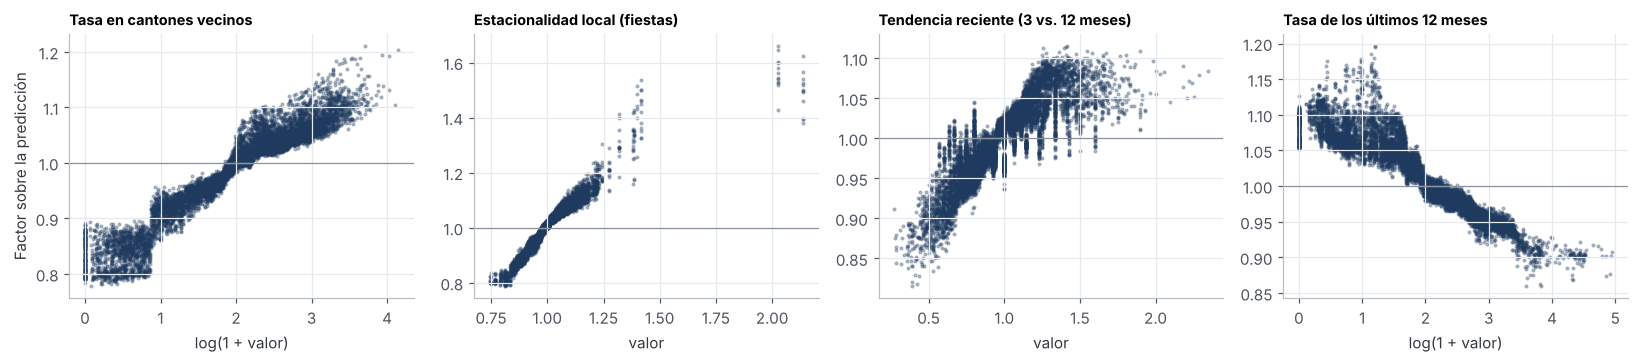

In [5]:
vars_dep = ['tasa_vecinos_lag_1', 'Estacional_canton', 'tendencia', 'tasa_media_12']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, v in zip(axes, vars_dep):
    x = muestra[v].astype(float)
    if v in ('tasa_vecinos_lag_1', 'tasa_media_12'):
        x = np.log1p(x)
    ax.scatter(x, np.exp(cm[v]), s=3, alpha=0.3, color=viz.AZUL, rasterized=True)
    ax.axhline(1, color=viz.GRIS, lw=0.8)
    ax.set_title(NOMBRE[v], fontsize=9.5)
    ax.set_xlabel('log(1 + valor)' if v in ('tasa_vecinos_lag_1', 'tasa_media_12') else 'valor')
axes[0].set_ylabel('Factor sobre la predicción')
fig.tight_layout()
fig.savefig(FIG / '05_dependencia_shap.png')

Cada punto es una predicción. Por encima de 1, la variable sube la predicción; por debajo, la baja. Se ven relaciones monótonas y razonables, lo que da confianza en que el modelo aprendió patrones con sentido y no ruido.

## 4. Una alerta explicada

El caso de la prueba con mayor riesgo previsto que terminó siendo un aumento real.

In [6]:
pp = pd.read_parquet(RAIZ / 'data' / 'processed' / 'predicciones_prueba.parquet')
pp['Mes'] = pd.PeriodIndex(pp['Mes'], freq='M')
prueba = prueba.merge(pp[['Canton', 'Delito', 'Mes', 'Aumento']], on=['Canton', 'Delito', 'Mes'], how='left').set_index(prueba.index)
prueba['riesgo'] = prueba['pred'] / (prueba['media_12'] + 0.5)
caso = prueba[(prueba['media_12'] >= 3) & (prueba['Aumento'] == 1)].sort_values('riesgo', ascending=False).iloc[0]
c = contrib.loc[caso.name, modelo.VARIABLES].sort_values(key=np.abs, ascending=False).head(8)
print(f"{caso.Canton.title()} · {ET[caso.Delito]} · {caso.Mes}")
print(f"Media 12 meses: {caso.media_12:.1f} · Predicción: {caso.pred:.1f} · Real: {caso.Delitos:.0f}")

Santa Cruz · Hurto · 2025-01
Media 12 meses: 32.3 · Predicción: 56.2 · Real: 96


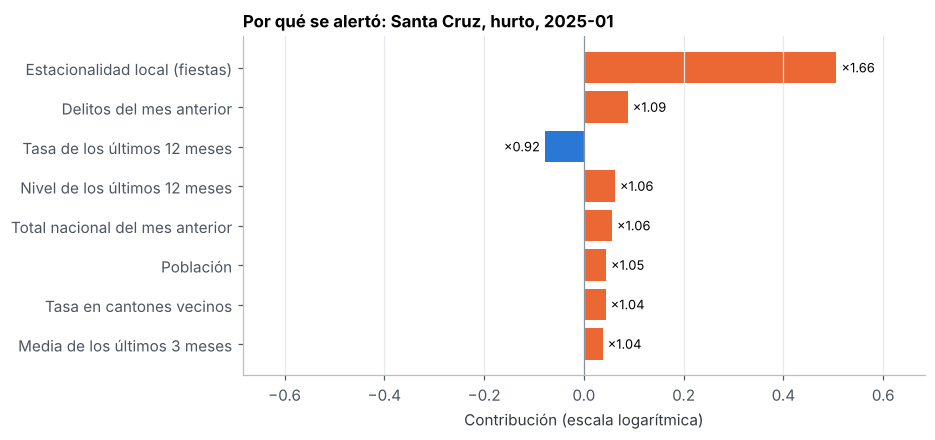

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
c = c[::-1]
ax.barh([NOMBRE[v] for v in c.index], c.values, color=[viz.NARANJA if x > 0 else viz.AZUL_MEDIO for x in c.values])
for i, x in enumerate(c.values):
    ax.text(x + (0.01 if x > 0 else -0.01), i, f'×{np.exp(x):.2f}', va='center', ha='left' if x > 0 else 'right', fontsize=8.5)
ax.axvline(0, color=viz.GRIS, lw=0.8); ax.grid(axis='y', visible=False)
lim = np.abs(c.values).max() * 1.35; ax.set_xlim(-lim, lim)
ax.set_xlabel('Contribución (escala logarítmica)')
ax.set_title(f"Por qué se alertó: {caso.Canton.title()}, {ET[caso.Delito].lower()}, {caso.Mes}")
fig.savefig(FIG / '05_alerta_explicada.png')

Así es como el sistema presentará cada alerta: no solo *dónde*, sino también *por qué*, en un lenguaje que un responsable de seguridad puede verificar.

## 5. Valor de negocio de las alertas

Supongamos que cada mes se revisan las **10 alertas** con mayor riesgo de aumento (entre cantones y delitos con al menos 3 casos mensuales de media). ¿Qué se habría conseguido en los 21 meses de prueba con cada criterio?

In [8]:
pp_f = pp[pp['media_12'] >= 3]
def valor(col):
    filas = []
    for _, g in pp_f.groupby('Mes'):
        top = g.loc[(g[col] / (g['media_12'] + 0.5)).nlargest(10).index]
        filas.append({'Aumentos reales detectados': top['Aumento'].sum(),
                      'Delitos por encima de lo habitual': (top['Delitos'] - top['media_12']).sum()})
    return pd.DataFrame(filas).sum()

criterios = {'Tendencia reciente': 'Media 3', 'Mes anterior': 'Ingenuo', 'SARIMA': 'SARIMA', 'LightGBM': 'LightGBM'}
negocio = pd.DataFrame({n: valor(c) for n, c in criterios.items()}).T
negocio['Alertas revisadas'] = 10 * pp_f['Mes'].nunique()
negocio.round(0).astype(int)

,Aumentos reales detectados,Delitos por encima de lo habitual,Alertas revisadas
Tendencia reciente,17,125,210
Mes anterior,16,55,210
SARIMA,15,163,210
LightGBM,32,544,210


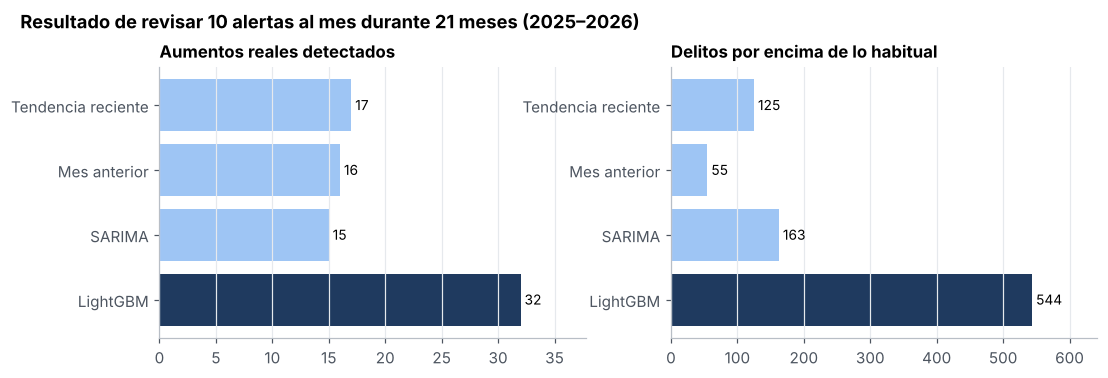

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col in zip(axes, ['Aumentos reales detectados', 'Delitos por encima de lo habitual']):
    v = negocio[col]
    ax.barh(v.index[::-1], v.values[::-1], color=[viz.AZUL if n == 'LightGBM' else '#9ec5f4' for n in v.index[::-1]])
    for i, x in enumerate(v.values[::-1]):
        ax.text(x, i, f' {x:,.0f}', va='center', fontsize=9)
    ax.set_title(col); ax.grid(axis='y', visible=False); ax.set_xlim(0, v.max() * 1.18)
fig.suptitle('Resultado de revisar 10 alertas al mes durante 21 meses (2025–2026)', x=0.01, ha='left', fontweight='bold', y=1.04)
fig.savefig(FIG / '05_valor_negocio.png')

**Lectura:** con el mismo esfuerzo (210 alertas revisadas en 21 meses), las alertas del LightGBM señalan **el doble de aumentos reales** que el criterio de tendencia reciente. Además, en los casos señalados ocurrieron **varias veces más delitos por encima de lo habitual**: son los lugares y momentos donde un refuerzo preventivo tenía más margen de impacto. Las cifras exactas están en la tabla anterior.

## 6. El sistema en funcionamiento: pronóstico para el próximo mes

Se reentrena el modelo con **todos los datos disponibles** (hasta septiembre de 2026), con la misma configuración elegida en el notebook 04, y se pronostica **octubre de 2026**. Es exactamente lo que haría el sistema en producción cada vez que el OIJ publica datos nuevos.

In [10]:
config = json.loads((MODELOS / 'lgbm_config.json').read_text())
ultimo = panel.dropna(subset=['Delitos'])['Mes'].max()
siguiente = ultimo + 1
X_prod = modelo.construir_variables(panel, RAIZ, ultimo)
entreno = X_prod[(X_prod['Mes'] <= ultimo)].dropna(subset=['lag_12', 'media_12'])
prod = lgb.LGBMRegressor(objective='poisson', n_estimators=int(config['arboles']), learning_rate=0.03,
                         num_leaves=int(config['num_leaves']), min_child_samples=int(config['min_child_samples']),
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, verbose=-1, random_state=0)
prod.fit(entreno[modelo.VARIABLES], entreno['Delitos'], init_score=modelo.offset(entreno))
prod.booster_.save_model(str(MODELOS / 'lgbm_produccion.txt'))

futuro = X_prod[X_prod['Mes'] == siguiente].copy()
futuro['Prevision'] = modelo.predecir(prod.booster_, futuro)
futuro['Riesgo'] = futuro['Prevision'] / (futuro['media_12'] + 0.5)
print(f'Entrenado con datos hasta {ultimo}. Pronóstico para {siguiente}: {futuro.Prevision.sum():,.0f} delitos previstos en el país.')

Entrenado con datos hasta 2026-09. Pronóstico para 2026-10: 3,013 delitos previstos en el país.


### 6.1 Dónde se concentrará la carga de trabajo

In [11]:
carga = futuro.groupby('Canton').agg(Prevision=('Prevision', 'sum'), Habitual=('media_12', 'sum'))
carga = carga.sort_values('Prevision', ascending=False).head(10)
carga.index = carga.index.str.title()
carga.round(0).astype(int).rename(columns={'Prevision': 'Delitos previstos', 'Habitual': 'Media 12 meses'})

,Delitos previstos,Media 12 meses
Canton,,
San Jose,673,699
Alajuela,226,218
Desamparados,97,89
Puntarenas,95,106
Heredia,92,90
Cartago,89,89
Limon,88,78
Liberia,82,89
San Carlos,78,82


### 6.2 Alertas de aumento: dónde se espera que el delito suba más de lo habitual

In [12]:
contrib_f = modelo.contribuciones(prod.booster_, futuro)
def motivos(i, n=3):
    c = contrib_f.loc[i, modelo.VARIABLES]
    c = c[c > 0].sort_values(ascending=False).head(n)
    return '; '.join(f'{NOMBRE[v].lower()} (×{np.exp(x):.2f})' for v, x in c.items())

candidatas = futuro[futuro['media_12'] >= 3].sort_values('Riesgo', ascending=False).head(10)
alertas = pd.DataFrame({
    'Cantón': candidatas['Canton'].str.title(), 'Delito': candidatas['Delito'].map(ET),
    'Media 12 meses': candidatas['media_12'].round(1), 'Previsto': candidatas['Prevision'].round(1),
    'Variación': (candidatas['Riesgo'] - 1).map('{:+.0%}'.format),
    'Principales motivos': [motivos(i) for i in candidatas.index],
}).reset_index(drop=True)
alertas.index += 1
with pd.option_context('display.max_colwidth', 120):
    display(alertas)

,Cantón,Delito,Media 12 meses,Previsto,Variación,Principales motivos
1,Montes De Oca,Robo de vehículo,8.7,11.3,+23%,tendencia reciente (3 vs. 12 meses) (×1.10); delitos del mes anterior (×1.10); nivel de los últimos 12 meses (×1.07)
2,Belen,Hurto,4.6,6.1,+20%,estacionalidad local (fiestas) (×1.33); tasa en cantones vecinos (×1.08); nivel de los últimos 12 meses (×1.06)
3,Limon,Hurto,13.0,16.1,+19%,delitos del mes anterior (×1.08); nivel de los últimos 12 meses (×1.06); perfil delictivo del cantón (×1.06)
4,Limon,Robo de vehículo,18.8,22.6,+17%,delitos del mes anterior (×1.12); tendencia reciente (3 vs. 12 meses) (×1.09); nivel de los últimos 12 meses (×1.07)
5,Escazu,Robo,3.5,4.6,+16%,nivel de los últimos 12 meses (×1.08); tendencia reciente (3 vs. 12 meses) (×1.07); población (×1.06)
6,Talamanca,Robo de vehículo,7.4,9.1,+14%,estacionalidad local (fiestas) (×1.10); nivel de los últimos 12 meses (×1.07); perfil delictivo del cantón (×1.07)
7,Alajuelita,Robo,3.1,4.1,+14%,nivel de los últimos 12 meses (×1.08); población (×1.08); tasa de los últimos 12 meses (×1.07)
8,Desamparados,Hurto,17.3,20.3,+14%,delitos del mes anterior (×1.10); tendencia reciente (3 vs. 12 meses) (×1.08); población (×1.07)
9,Belen,Robo,3.8,4.8,+14%,estacionalidad local (fiestas) (×1.24); nivel de los últimos 12 meses (×1.09); tendencia reciente (3 vs. 12 meses) (...
10,Limon,Homicidio,7.6,9.1,+13%,población (×1.10); tendencia reciente (3 vs. 12 meses) (×1.08); nivel de los últimos 12 meses (×1.08)


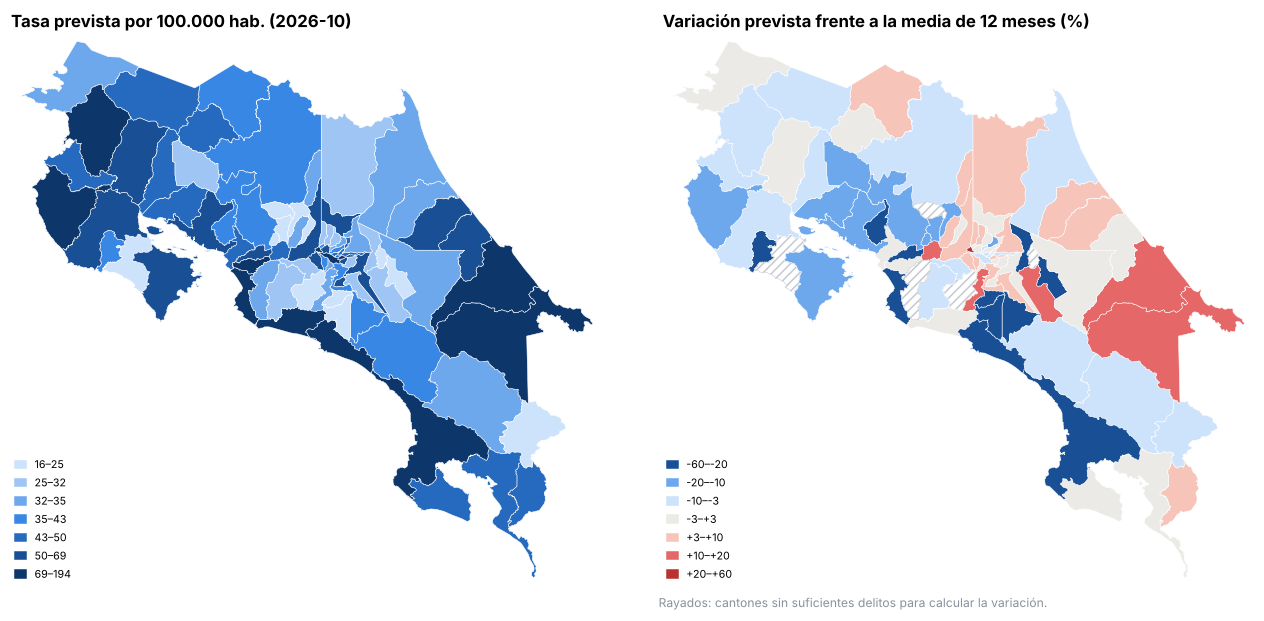

In [13]:
riesgo_canton = futuro[futuro['media_12'] >= 1].groupby('Canton').apply(
    lambda g: g['Prevision'].sum() / (g['media_12'].sum() + 0.5) - 1)
geo = viz.cargar_geometrias(RAIZ / 'data' / 'external' / 'cantones.geojson')
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
viz.mapa(axes[0], geo, futuro.groupby('Canton')['Prevision'].sum() / futuro.groupby('Canton')['Poblacion'].first() * 1e5,
         titulo=f'Tasa prevista por 100.000 hab. ({siguiente})')
viz.mapa(axes[1], geo, riesgo_canton * 100, cortes=[-60, -20, -10, -3, 3, 10, 20, 60],
         titulo='Variación prevista frente a la media de 12 meses (%)', formato='{:+.0f}',
         rampa=viz.RAMPA_DIVERGENTE)
fig.text(0.52, -0.01, 'Rayados: cantones sin suficientes delitos para calcular la variación.', fontsize=8, color=viz.GRIS)
fig.tight_layout()
fig.savefig(FIG / '05_pronostico_mes_siguiente.png')

In [14]:
cols = ['Canton', 'Provincia', 'Delito', 'Mes', 'Prevision', 'media_12', 'Riesgo', 'Poblacion']
futuro[cols].assign(Mes=futuro['Mes'].astype(str)).to_parquet(RAIZ / 'data' / 'processed' / 'pronostico_mes_siguiente.parquet', index=False)
print('Pronóstico guardado')

Pronóstico guardado


## 7. Conclusiones

1. **El modelo es interpretable:** sus predicciones se explican con factores que tienen sentido para un responsable de seguridad (impulso reciente, regresión a la media, contagio desde cantones vecinos, fiestas locales y contexto nacional).
2. **Cada alerta llega con sus motivos**, lo que permite verificarla antes de actuar en lugar de confiar a ciegas en el modelo.
3. **Con el mismo esfuerzo, las alertas del modelo señalan el doble de aumentos reales** que el criterio de tendencia reciente durante los 21 meses de prueba.
4. **El sistema ya funciona de punta a punta:** con los datos publicados hasta septiembre de 2026 genera el pronóstico, las alertas y los mapas de octubre de 2026. El siguiente paso es empaquetarlo en una aplicación (Streamlit) que lo haga automáticamente.